## 14. Estabilidade de sistemas lineares

No Notebook 11 reconhecemos os cinco tipos de ponto crítico de um sistema $\mathbf{y}'=\mathbf{A}\mathbf{y}$ — nó impróprio, nó próprio, ponto de sela, centro e ponto espiral — **pelo desenho** do retrato de fase, e vimos uma primeira ideia de estabilidade. No Notebook 13 aprendemos a escrever a solução geral desses sistemas a partir dos autovalores e autovetores de $\mathbf{A}$.

Neste notebook juntamos as duas coisas: a forma da solução geral explica *por que* cada matriz produz um determinado retrato de fase, e isso permite decidir o tipo e a estabilidade de um ponto crítico **sem desenhar e sem resolver o sistema** — olhando apenas para os autovalores de $\mathbf{A}$ ou, ainda mais simples, para o seu traço e o seu determinante. No fim, aplicamos as ideias a sistemas com ponto crítico fora da origem e a um sistema mecânico de duas massas e três molas.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp
sp.init_printing()

def retrato_de_fase(A, b=(0, 0), xlim=(-4, 4), ylim=(-3, 3), iniciais=(), T=20, ax=None):
    """Desenha o retrato de fase de y' = A y + b: linhas de fluxo, trajetórias que
    passam pelos pontos em `iniciais` (calculadas para t em [-T, T], parando quando
    saem da janela) e o ponto crítico."""
    A = np.array(A, dtype=float)
    b = np.array(b, dtype=float)
    if ax is None:
        ax = plt.gca()
    Y1, Y2 = np.meshgrid(np.linspace(*xlim, 30), np.linspace(*ylim, 30))
    V1 = A[0,0]*Y1 + A[0,1]*Y2 + b[0]
    V2 = A[1,0]*Y1 + A[1,1]*Y2 + b[1]
    ax.streamplot(Y1, Y2, V1, V2, color='lightblue', density=1.2, linewidth=1)

    F = lambda t, y: A @ y + b
    # evento: interrompe a integração quando a trajetória se afasta bastante da janela
    cx, cy = np.mean(xlim), np.mean(ylim)
    lx, ly = xlim[1] - xlim[0], ylim[1] - ylim[0]
    fora = lambda t, y: max(abs(y[0] - cx)/lx, abs(y[1] - cy)/ly) - 1
    fora.terminal = True
    for y0 in iniciais:
        for t_final in (T, -T):                      # para a frente e para trás no tempo
            s = solve_ivp(F, (0, t_final), y0, max_step=0.02, events=fora)
            ax.plot(s.y[0], s.y[1], 'r-', lw=1.2)
        ax.plot(*y0, 'ko', ms=3)

    if np.linalg.det(A) != 0:
        eq = np.linalg.solve(A, -b)
        ax.plot(*eq, 'o', color='navy', ms=6)        # ponto crítico
    ax.set_xlim(xlim); ax.set_ylim(ylim)
    ax.set_xlabel('$y_1$'); ax.set_ylabel('$y_2$')
    return ax

### 14.1 Tipos de ponto crítico e autovalores

Considere o sistema $\mathbf{y}'=\mathbf{A}\mathbf{y}$, com $\mathbf{A}$ uma matriz real $2\times2$ com $\det\mathbf{A}\neq0$ (de modo que a origem é o único ponto crítico e nenhum autovalor é nulo). A solução geral do Notebook 13 mostra o que acontece em cada caso:

- **Autovalores reais distintos e de mesmo sinal** ($\lambda_1,\lambda_2<0$ ou $\lambda_1,\lambda_2>0$): $\mathbf{y}=c_1\mathbf{v}_1e^{\lambda_1t}+c_2\mathbf{v}_2e^{\lambda_2t}$. Se ambos são negativos, as duas exponenciais decaem e todas as trajetórias entram na origem; o termo que decai mais devagar (o de menor $|\lambda|$) domina perto da origem, e por isso as trajetórias chegam tangentes à reta do seu autovetor. É um **nó impróprio**, assintoticamente estável. Se ambos são positivos, a figura é a mesma, percorrida no sentido contrário: nó impróprio instável.
- **Autovalores reais de sinais opostos** ($\lambda_1<0<\lambda_2$): só as soluções sobre a reta de $\mathbf{v}_1$ ($c_2=0$) entram na origem; todas as outras acabam se afastando ao longo da reta de $\mathbf{v}_2$. É um **ponto de sela**, sempre instável (Exemplo 13.1).
- **Autovalores reais iguais** ($\lambda_1=\lambda_2=\lambda$): se há dois autovetores independentes, todo vetor é autovetor ($\mathbf{A}=\lambda\mathbf{I}$) e as trajetórias são semirretas: **nó próprio**. Se há só um, a solução tem o termo $\mathbf{v}te^{\lambda t}$ e as trajetórias têm a forma de "S" do Exemplo 13.4: **nó impróprio degenerado**. Em ambos os casos, assintoticamente estável se $\lambda<0$ e instável se $\lambda>0$.
- **Autovalores complexos** $\alpha\pm i\beta$ com $\alpha\neq0$: as soluções são senos e cossenos de frequência $\beta$ multiplicados por $e^{\alpha t}$ (Seção 13.3) — as trajetórias giram e se aproximam da origem ($\alpha<0$) ou se afastam dela ($\alpha>0$): **ponto espiral**, assintoticamente estável ou instável.
- **Autovalores imaginários puros** $\pm i\beta$: as soluções são periódicas, de período $2\pi/\beta$, e as trajetórias são curvas fechadas (elipses): **centro**, estável, mas não assintoticamente estável.

Resumindo (Boyce e DiPrima, 2020, Seção 9.1):

| Autovalores | Tipo de ponto crítico | Estabilidade |
|---|---|---|
| $\lambda_1>\lambda_2>0$ | nó impróprio | instável |
| $\lambda_1<\lambda_2<0$ | nó impróprio | assintoticamente estável |
| $\lambda_2<0<\lambda_1$ | ponto de sela | instável |
| $\lambda_1=\lambda_2>0$ | nó próprio ou impróprio degenerado | instável |
| $\lambda_1=\lambda_2<0$ | nó próprio ou impróprio degenerado | assintoticamente estável |
| $\alpha\pm i\beta$, $\alpha>0$ | ponto espiral | instável |
| $\alpha\pm i\beta$, $\alpha<0$ | ponto espiral | assintoticamente estável |
| $\pm i\beta$ | centro | estável |

Lembrando as noções do Notebook 11: um ponto crítico é **estável** se as soluções que começam suficientemente perto dele permanecem perto dele para todo $t>0$; é **assintoticamente estável** se, além disso, elas convergem para ele quando $t\to\infty$; e é **instável** se não é estável. Para sistemas lineares de qualquer tamanho, a tabela se resume a uma regra simples sobre as **partes reais** dos autovalores:

- se todos os autovalores têm parte real **negativa**, a origem é assintoticamente estável (todas as exponenciais decaem);
- se algum autovalor tem parte real **positiva**, a origem é instável (há soluções que crescem exponencialmente);
- se todos têm parte real $\le0$ e os de parte real nula são imaginários puros simples, a origem é estável, mas não assintoticamente estável (as soluções correspondentes oscilam sem decair).

### 14.2 Critérios pelo traço e pelo determinante

Na Seção 12.3.1 vimos que o polinômio característico de uma matriz $2\times2$ é $\lambda^2-p\lambda+q$, com

$$
p=\operatorname{tr}\mathbf{A}=\lambda_1+\lambda_2,\qquad q=\det\mathbf{A}=\lambda_1\lambda_2,
$$

e que, portanto, os autovalores são $\lambda=\frac12\left(p\pm\sqrt{\Delta}\right)$, com o discriminante $\Delta=p^2-4q$. Os três números $p$, $q$ e $\Delta$ bastam para decidir em que linha da tabela da Seção 14.1 estamos (Kreyszig, 2008):

- $\Delta<0$ (autovalores complexos): **centro** se $p=0$ (parte real $p/2$ nula) e **ponto espiral** se $p\neq0$;
- $\Delta\ge0$ (autovalores reais): **ponto de sela** se $q<0$ (o produto é negativo, então os sinais são opostos) e **nó** se $q>0$ (mesmo sinal) — impróprio se $\Delta>0$, próprio ou impróprio degenerado se $\Delta=0$.

E, para a estabilidade:

| Critério | Estabilidade |
|---|---|
| $p<0$ e $q>0$ | assintoticamente estável |
| $p\le0$ e $q>0$ | estável |
| $p>0$ ou $q<0$ | instável |

(De fato: com $q>0$, os autovalores reais têm o mesmo sinal, que é o sinal de $p$, e os complexos têm parte real $p/2$; com $q<0$ há um autovalor positivo.) Kreyszig chama o ponto assintoticamente estável de **estável e atrativo**.

A função abaixo implementa esses critérios. Para um nó com $\Delta=0$, ela distingue o nó próprio ($\mathbf{A}=\lambda\mathbf{I}$) do impróprio degenerado.

In [2]:
def classifica(A, tol=1e-12):
    '''Tipo e estabilidade do ponto crítico na origem de y' = A y (A 2x2), pelo traço p,
    pelo determinante q e pelo discriminante Δ = p² - 4q.'''
    A = np.array(A, dtype=float)
    p, q = np.trace(A), np.linalg.det(A)
    D = p**2 - 4*q
    if abs(q) < tol:
        return 'det A = 0: a origem não é um ponto crítico isolado'
    if q < 0:
        return 'ponto de sela (instável)'
    estab = 'assintoticamente estável' if p < -tol else 'instável'
    if D < -tol:
        if abs(p) < tol:
            return 'centro (estável, mas não assintoticamente estável)'
        return 'ponto espiral ' + estab
    if abs(D) <= tol:
        if np.allclose(A, A[0, 0]*np.eye(2)):
            return 'nó próprio ' + estab
        return 'nó impróprio degenerado ' + estab
    return 'nó impróprio ' + estab

É útil visualizar esses critérios no **plano traço–determinante**, em que cada matriz $2\times2$ é representada pelo ponto $(p,q)$. A parábola $\Delta=0$, isto é, $q=p^2/4$, separa os nós (abaixo dela, com $q>0$) das espirais (acima dela); o semieixo $p=0$, $q>0$ é o dos centros; o semiplano $q<0$, o das selas; e o lado esquerdo ($p<0$) é o dos pontos estáveis.

In [3]:
def plano_traco_det(pontos=None, ax=None, lim=7):
    '''Desenha o plano traço-determinante com as regiões de cada tipo de ponto crítico e,
    opcionalmente, os pontos (p, q) das matrizes do dicionário {rótulo: matriz}.'''
    if ax is None:
        ax = plt.gca()
    p = np.linspace(-lim, lim, 400)
    qmax = lim**2/4 + 2
    ax.fill_between(p, -qmax, 0, color='tab:red', alpha=0.08)                       # selas
    ax.fill_between(p, 0, p**2/4, where=p < 0, color='tab:green', alpha=0.15)       # nós estáveis
    ax.fill_between(p, 0, p**2/4, where=p > 0, color='tab:orange', alpha=0.15)      # nós instáveis
    ax.fill_between(p, p**2/4, qmax, where=p < 0, color='tab:green', alpha=0.05)    # espirais estáveis
    ax.fill_between(p, p**2/4, qmax, where=p > 0, color='tab:orange', alpha=0.05)   # espirais instáveis
    ax.plot(p, p**2/4, 'k-', lw=1, label=r'$\Delta=0$: $q=p^2/4$')
    ax.plot([0, 0], [0, qmax], 'b-', lw=2, label='centros ($p=0$, $q>0$)')
    ax.axhline(0, color='k', lw=0.8)
    for x, y, texto in [(0, -qmax/2, 'selas'), (-0.75*lim, 0.06*lim**2, 'nós\nestáveis'),
                        (0.75*lim, 0.06*lim**2, 'nós\ninstáveis'), (-0.35*lim, 0.8*qmax, 'espirais\nestáveis'),
                        (0.35*lim, 0.8*qmax, 'espirais\ninstáveis')]:
        ax.text(x, y, texto, ha='center', va='center', fontsize=9, color='0.3')
    for rotulo, A in (pontos or {}).items():
        A = np.array(A, dtype=float)
        ax.plot(np.trace(A), np.linalg.det(A), 'o', ms=6)
        ax.annotate(rotulo, (np.trace(A), np.linalg.det(A)), textcoords='offset points', xytext=(5, 5), fontsize=9)
    ax.set_xlim(-lim, lim); ax.set_ylim(-qmax, qmax)
    ax.set_xlabel('traço $p$'); ax.set_ylabel('determinante $q$')
    ax.legend(loc='lower right', fontsize=8, framealpha=1)
    return ax

**Exemplo 14.1:** Classificar, pelos critérios do traço e do determinante, os pontos críticos dos sistemas dos Exemplos 13.1, 13.3 e 13.4 e da Atividade 13.2, conferir com os autovalores e localizá-los no plano traço–determinante.

Ex. 13.1:  p =  1.00,  q = -2.00,  Δ =   9.00,  autovalores = [ 2. -1.]  ->  ponto de sela (instável)
Ex. 13.3:  p = -1.00,  q =  1.25,  Δ =  -4.00,  autovalores = [-0.5+1.j -0.5-1.j]  ->  ponto espiral assintoticamente estável
Ex. 13.4:  p =  4.00,  q =  4.00,  Δ =   0.00,  autovalores = [2. 2.]  ->  nó impróprio degenerado instável
At. 13.2:  p =  2.00,  q =  2.00,  Δ =  -4.00,  autovalores = [1.+1.j 1.-1.j]  ->  ponto espiral instável


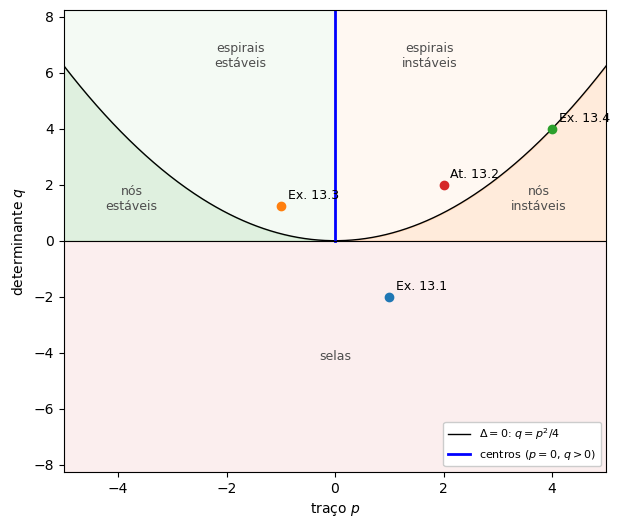

In [4]:
exemplos = {'Ex. 13.1': [[3, -1], [4, -2]],
            'Ex. 13.3': [[-0.5, 1], [-1, -0.5]],
            'Ex. 13.4': [[1, -1], [1, 3]],
            'At. 13.2': [[0, -2], [1, 2]]}
for nome, A in exemplos.items():
    A = np.array(A, dtype=float)
    p, q = np.trace(A), np.linalg.det(A)
    print(f'{nome}:  p = {p:5.2f},  q = {q:5.2f},  Δ = {p**2 - 4*q:6.2f},  autovalores = {np.round(np.linalg.eigvals(A), 3)}'
          f'  ->  {classifica(A)}')

plt.figure(figsize=(7, 6))
plano_traco_det(exemplos, lim=5)
plt.show()

O Exemplo 13.1 ($q=-2<0$) é um ponto de sela; o Exemplo 13.3 ($\Delta<0$, $p<0$), um ponto espiral assintoticamente estável; o Exemplo 13.4 fica exatamente **sobre** a parábola ($\Delta=0$, autovalor duplo $2$), com $p>0$: nó impróprio degenerado instável; e a Atividade 13.2 ($\Delta<0$, $p>0$), um ponto espiral instável — tudo de acordo com os retratos de fase desenhados no Notebook 13.

Note que os casos de fronteira — centros ($p=0$) e nós com autovalor repetido ($\Delta=0$) — ocupam curvas no plano, e não regiões: uma perturbação arbitrariamente pequena dos coeficientes de $\mathbf{A}$ pode transformar um centro numa espiral (estável ou instável) ou um nó degenerado num nó impróprio ou numa espiral. Por isso, em modelos com coeficientes medidos experimentalmente, esses casos exigem cuidado.

#### Atividade 14.1

Classifique, pelos critérios do traço e do determinante, os pontos críticos dos sistemas $\mathbf{y}'=\mathbf{A}\mathbf{y}$ com as matrizes abaixo (todas já apareceram nos Notebooks 12 e 13), confira com os autovalores e com a função `classifica` e localize-as no plano traço–determinante.

a) $\begin{bmatrix}5&-1\\3&1\end{bmatrix}$ (Atividade 12.1)
$\qquad$ b) $\begin{bmatrix}1&-5\\1&-3\end{bmatrix}$ (Exercício 4(a) do Notebook 13)
$\qquad$ c) $\begin{bmatrix}2&-5\\1&-2\end{bmatrix}$
$\qquad$ d) $\begin{bmatrix}3&-4\\1&-1\end{bmatrix}$

### 14.3 Revisitando os exemplos do Notebook 11

**Exemplo 14.2:** Explicar, pelos autovalores, os cinco retratos de fase dos Exemplos 11.1 a 11.5.

*Solução:* calculamos os autovalores (com o SymPy, para tê-los de forma exata), os critérios $p$, $q$, $\Delta$ e a classificação de cada matriz:

Ex. 11.1:  autovalores = [-2, -4],  p = -6,  q = 8,  Δ = 4  ->  nó impróprio assintoticamente estável
Ex. 11.2:  autovalores = [1],  p = 2,  q = 1,  Δ = 0  ->  nó próprio instável
Ex. 11.3:  autovalores = [1, -1],  p = 0,  q = -1,  Δ = 4  ->  ponto de sela (instável)
Ex. 11.4:  autovalores = [-2*I, 2*I],  p = 0,  q = 4,  Δ = -16  ->  centro (estável, mas não assintoticamente estável)
Ex. 11.5:  autovalores = [-1 - I, -1 + I],  p = -2,  q = 2,  Δ = -4  ->  ponto espiral assintoticamente estável


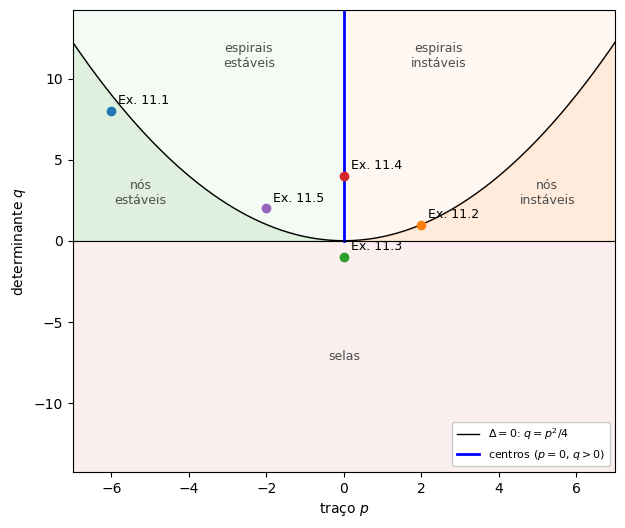

In [5]:
nb11 = {'11.1': [[-3, 1], [1, -3]],
        '11.2': [[1, 0], [0, 1]],
        '11.3': [[1, 0], [0, -1]],
        '11.4': [[0, 1], [-4, 0]],
        '11.5': [[-1, 1], [-1, -1]]}
for nome, A in nb11.items():
    M = sp.Matrix(A)
    p, q = M.trace(), M.det()
    print(f'Ex. {nome}:  autovalores = {list(M.eigenvals())},  p = {p},  q = {q},  Δ = {p**2 - 4*q}  ->  {classifica(A)}')

plt.figure(figsize=(7, 6))
plano_traco_det({f'Ex. {k}': A for k, A in nb11.items()}, lim=7)
plt.show()

Agora cada desenho do Notebook 11 tem uma explicação:

- **Exemplo 11.1** (nó impróprio, assintoticamente estável): autovalores $-4$ e $-2$, com autovetores $(1,-1)$ e $(1,1)$ (Exemplos 12.1 e 12.2). O termo $e^{-4t}$ decai mais rápido que $e^{-2t}$, então perto da origem sobra $c_1(1,1)e^{-2t}$: é por isso que as trajetórias chegam tangentes à reta $y_2=y_1$, a do autovetor do autovalor de **menor** valor absoluto.
- **Exemplo 11.2** (nó próprio, instável): $\mathbf{A}=\mathbf{I}$ tem o autovalor duplo $1$ e **todo** vetor é autovetor, então toda solução é $\mathbf{y}=\mathbf{y}_0e^{t}$: as trajetórias são semirretas saindo da origem em todas as direções.
- **Exemplo 11.3** (ponto de sela): autovalores $1$ e $-1$, com autovetores sobre os eixos — as duas trajetórias que entram na origem estão sobre o eixo $y_2$ (autovalor $-1$) e as duas que saem, sobre o eixo $y_1$ (autovalor $1$).
- **Exemplo 11.4** (centro): autovalores $\pm2i$, com $p=0$. As soluções são combinações de $\cos2t$ e $\operatorname{sen}2t$, de período $\pi$ — o mesmo resultado obtido no Notebook 11 pela redução a $y_1''+4y_1=0$.
- **Exemplo 11.5** (ponto espiral, assintoticamente estável): autovalores $-1\pm i$. A parte real $-1$ dá o decaimento $e^{-t}$ da distância até a origem (é por isso que, no gráfico de $\|\mathbf{y}(t)\|$ em escala logarítmica da Seção 11.6, a curva desse exemplo é uma reta) e a parte imaginária $1$ dá a frequência da rotação.

No plano traço–determinante, os cinco exemplos ficam em cinco regiões (ou curvas) diferentes. O Exemplo 11.2 fica sobre a parábola ($\Delta=0$), no lado instável, e o Exemplo 11.4, sobre o semieixo dos centros.

### 14.4 Pontos críticos fora da origem

Para um sistema autônomo $\mathbf{x}'=\mathbf{A}\mathbf{x}+\mathbf{b}$ com $\det\mathbf{A}\neq0$, o único ponto crítico é $\mathbf{x}^*=-\mathbf{A}^{-1}\mathbf{b}$ (Seção 10.4). Com a translação $\mathbf{z}=\mathbf{x}-\mathbf{x}^*$ (Seção 11.7) obtemos

$$
\mathbf{z}'=\mathbf{x}'=\mathbf{A}\mathbf{x}+\mathbf{b}=\mathbf{A}(\mathbf{z}+\mathbf{x}^*)+\mathbf{b}=\mathbf{A}\mathbf{z},
$$

pois $\mathbf{A}\mathbf{x}^*+\mathbf{b}=\mathbf{0}$. Ou seja, o vetor $\mathbf{b}$ só **desloca** o ponto crítico; o tipo e a estabilidade de $\mathbf{x}^*$ são os da origem para $\mathbf{z}'=\mathbf{A}\mathbf{z}$, e são decididos pelos autovalores de $\mathbf{A}$ (ou pelo seu traço e determinante), como antes. Além disso, a solução geral é $\mathbf{x}(t)=\mathbf{x}^*+\mathbf{z}(t)$, com $\mathbf{z}$ dada pelos autovalores e autovetores de $\mathbf{A}$.

**Exemplo 14.3:** Classificar o ponto de equilíbrio dos tanques interligados do Exemplo 10.6,

$$
\frac{d\mathbf{Q}}{dt}=\begin{bmatrix}-0{,}1&0{,}075\\0{,}1&-0{,}2\end{bmatrix}\mathbf{Q}+\begin{bmatrix}1{,}5\\3\end{bmatrix},
$$

e explicar, pelos autovalores, a forma da solução $Q_1(t)=42+7e^{-t/4}+6e^{-t/20}$, $Q_2(t)=36-14e^{-t/4}+4e^{-t/20}$ encontrada lá.

In [6]:
R = sp.Rational
K = sp.Matrix([[-R(1, 10), R(3, 40)], [R(1, 10), -R(1, 5)]])
b = sp.Matrix([R(3, 2), 3])
print('ponto de equilíbrio:', list(-K.inv()*b))
for val, m, vs in K.eigenvects():
    print(f'λ = {val}:  autovetor {list(vs[0])}')
print('p =', K.trace(), ',  q =', K.det(), ',  Δ =', K.trace()**2 - 4*K.det(), ' ->', classifica(K))

ponto de equilíbrio: [42, 36]
λ = -1/4:  autovetor [-1/2, 1]
λ = -1/20:  autovetor [3/2, 1]
p = -3/10 ,  q = 1/80 ,  Δ = 1/25  -> nó impróprio assintoticamente estável


Os autovalores são $-\frac14$ e $-\frac1{20}$, reais, distintos e negativos: o equilíbrio $(42,36)$ é um **nó impróprio assintoticamente estável** — por isso, no Exemplo 10.6, todas as trajetórias convergiam para ele. Os expoentes $-t/4$ e $-t/20$ da solução são exatamente os autovalores, e os vetores dos coeficientes, $(7,-14)$ e $(6,4)$, são múltiplos dos autovetores $(1,-2)$ e $(3,2)$.

O autovalor $-\frac1{20}$, de menor valor absoluto, governa a aproximação final ao equilíbrio: depois que o termo $e^{-t/4}$ desaparece, a distância ao equilíbrio diminui como $e^{-t/20}$, isto é, cai pela metade a cada $20\ln2\approx14$ minutos, e as trajetórias chegam ao equilíbrio tangentes à reta do autovetor $(3,2)$:

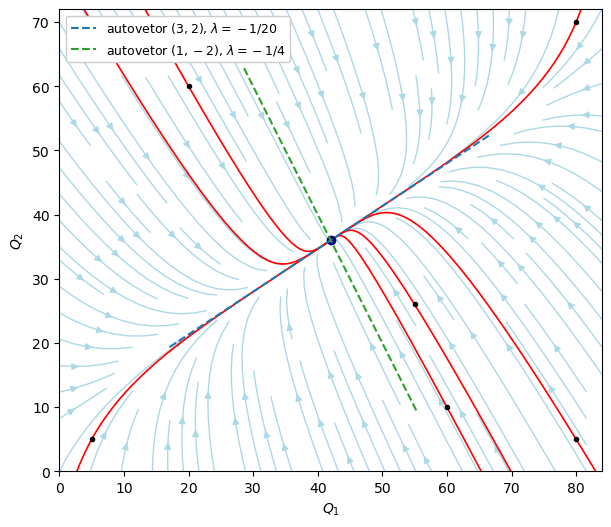

In [7]:
Kn = np.array(K, dtype=float)
bn = np.array(b, dtype=float).ravel()
Q_eq = np.array([42, 36])
fig, ax = plt.subplots(figsize=(7, 6))
retrato_de_fase(Kn, bn, xlim=(0, 84), ylim=(0, 72), ax=ax,
                iniciais=[(5, 5), (80, 5), (5, 70), (80, 70), (60, 10), (20, 60), (55, 26)], T=200)
s = np.array([-30, 30])
ax.plot(Q_eq[0] + 3*s/np.hypot(3, 2), Q_eq[1] + 2*s/np.hypot(3, 2), '--', color='tab:blue', lw=1.5,
        label=r'autovetor $(3,2)$, $\lambda=-1/20$')
ax.plot(Q_eq[0] + 1*s/np.hypot(1, 2), Q_eq[1] - 2*s/np.hypot(1, 2), '--', color='tab:green', lw=1.5,
        label=r'autovetor $(1,-2)$, $\lambda=-1/4$')
ax.set_xlabel('$Q_1$'); ax.set_ylabel('$Q_2$'); ax.legend(loc='upper left', fontsize=9, framealpha=1)
plt.show()

#### Atividade 14.2

Classifique, pelos autovalores, o ponto crítico $(16,16)$ do modelo da estufa do Exemplo 11.6, $\mathbf{u}'=\mathbf{K}\mathbf{u}+\mathbf{b}$, com $\mathbf{K}=\begin{bmatrix}-\frac{13}8&\frac34\\[1mm]\frac14&-\frac14\end{bmatrix}$ e $\mathbf{b}=(14,0)$. Escreva a solução geral na forma $\mathbf{u}(t)=\mathbf{u}^*+c_1\mathbf{v}_1e^{\lambda_1t}+c_2\mathbf{v}_2e^{\lambda_2t}$ e use-a para explicar o comportamento da solução do Exemplo 11.6: por que a temperatura da estufa sobe rapidamente no início e depois se aproxima do equilíbrio lentamente?

### 14.5 Aplicação: duas massas e três molas

**Exemplo 14.4:** (Adaptado de Boyce e DiPrima, 2020) Duas massas $m_1$ e $m_2$ estão presas entre duas paredes por três molas, de constantes $k_1$ (entre a parede e a primeira massa), $k_2$ (entre as massas) e $k_3$ (entre a segunda massa e a outra parede). Sem atrito e sem forças externas, sendo $x_1$ e $x_2$ os deslocamentos das massas em relação às posições de equilíbrio, as equações de movimento são

$$
\begin{aligned}
m_1x_1''&=-(k_1+k_2)x_1+k_2x_2,\\
m_2x_2''&=k_2x_1-(k_2+k_3)x_2.
\end{aligned}
$$

(É o sistema do Exemplo 10.4 com uma terceira mola ligando a segunda massa à parede.) Com $y_1=x_1$, $y_2=x_2$, $y_3=x_1'$ e $y_4=x_2'$, obtemos um sistema de quatro equações de 1ª ordem. Para $m_1=2$, $m_2=\frac94$, $k_1=1$, $k_2=3$ e $k_3=\frac{15}4$:

$$
\mathbf{y}'=\begin{bmatrix}0&0&1&0\\0&0&0&1\\-2&\frac32&0&0\\\frac43&-3&0&0\end{bmatrix}\mathbf{y}.
$$

Vamos calcular os autovalores, interpretar os movimentos possíveis e classificar a estabilidade do equilíbrio $\mathbf{y}=\mathbf{0}$.

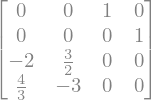

λ = -2*I:  autovetor [-3*I/8, I/2, -3/4, 1]
λ = -I:  autovetor [3*I/2, I, 3/2, 1]
λ = I:  autovetor [-3*I/2, -I, 3/2, 1]
λ = 2*I:  autovetor [3*I/8, -I/2, -3/4, 1]


In [8]:
def matriz_massas(m1, m2, k1, k2, k3, gama=0):
    '''Matriz do sistema y' = A y das duas massas e três molas, com y = (x1, x2, x1', x2')
    e, opcionalmente, um amortecimento -gama*xi' em cada massa.'''
    m1, m2, k1, k2, k3, gama = map(sp.nsimplify, (m1, m2, k1, k2, k3, gama))   # frações exatas
    return sp.Matrix([[0, 0, 1, 0],
                      [0, 0, 0, 1],
                      [-(k1 + k2)/m1, k2/m1, -gama/m1, 0],
                      [k2/m2, -(k2 + k3)/m2, 0, -gama/m2]])

R = sp.Rational
A = matriz_massas(2, R(9, 4), 1, 3, R(15, 4))
lamb = sp.symbols('lambda')
display(A, sp.Eq(sp.factor(A.charpoly(lamb).as_expr()), 0))
for val, m, vs in A.eigenvects():
    print(f'λ = {val}:  autovetor {list(vs[0])}')

A equação característica é $(\lambda^2+1)(\lambda^2+4)=0$: os autovalores são $\pm i$ e $\pm2i$, todos **imaginários puros**. Pela regra da Seção 14.1, o equilíbrio é **estável, mas não assintoticamente estável**: as massas oscilam para sempre, sem que a amplitude cresça ou decaia — o que faz sentido, pois sem atrito a energia mecânica se conserva.

Separando as partes real e imaginária de $\mathbf{v}e^{\lambda t}$ (Seção 13.3), as duas primeiras componentes (as posições) dos autovetores dizem **como** as massas se movem em cada frequência:

- para $\lambda=\pm i$, as posições são proporcionais a $(3,2)$: as duas massas oscilam **em fase**, com frequência 1 (período $2\pi$), a primeira com amplitude $3/2$ vezes a da segunda;
- para $\lambda=\pm2i$, as posições são proporcionais a $(3,-4)$: as massas oscilam **em oposição de fase**, com frequência 2 (período $\pi$).

Esses são os dois **modos normais** do sistema (como no Exemplo 10.4 e na Atividade 10.2). A solução geral é a combinação

$$
\begin{bmatrix}x_1\\x_2\end{bmatrix}=\begin{bmatrix}3\\2\end{bmatrix}\left(c_1\cos t+c_2\operatorname{sen}t\right)+\begin{bmatrix}3\\-4\end{bmatrix}\left(c_3\cos2t+c_4\operatorname{sen}2t\right).
$$

Vamos ver os dois modos e uma combinação deles, todos partindo do repouso:

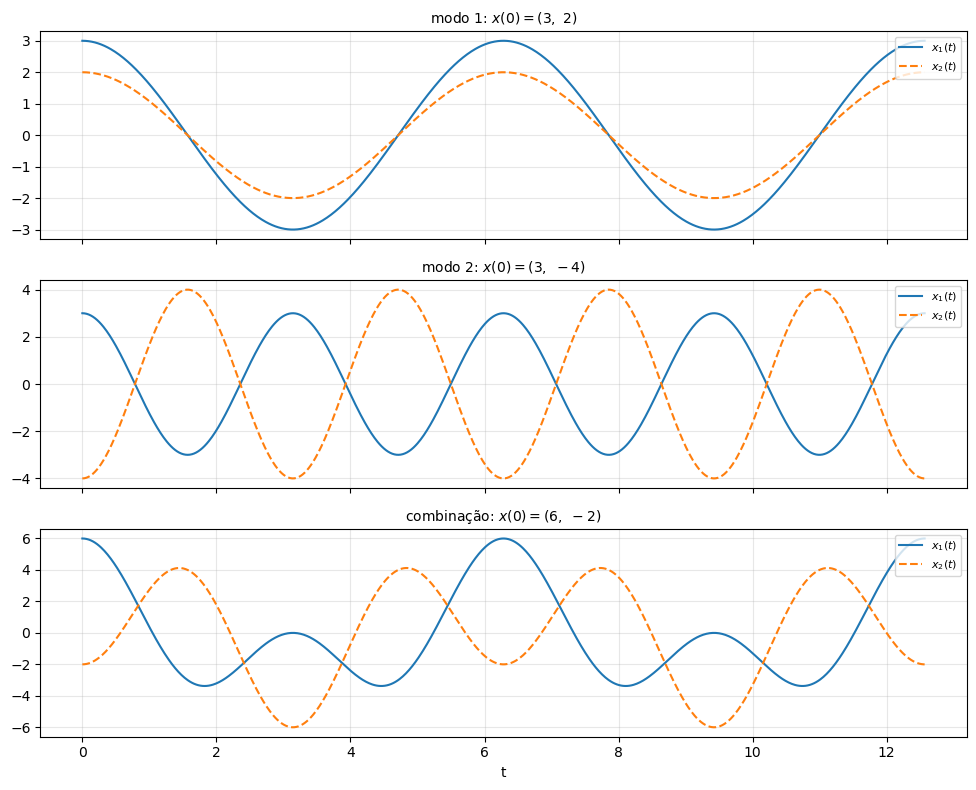

In [9]:
An = np.array(A, dtype=float)
ts = np.linspace(0, 4*np.pi, 800)
casos = [('modo 1: $x(0)=(3,\\ 2)$', [3, 2, 0, 0]),
         ('modo 2: $x(0)=(3,\\ -4)$', [3, -4, 0, 0]),
         ('combinação: $x(0)=(6,\\ -2)$', [6, -2, 0, 0])]
fig, axs = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for ax, (titulo, y0) in zip(axs, casos):
    s = solve_ivp(lambda t, y: An @ y, (ts[0], ts[-1]), y0, t_eval=ts, rtol=1e-10, atol=1e-12)
    ax.plot(s.t, s.y[0], label='$x_1(t)$')
    ax.plot(s.t, s.y[1], '--', label='$x_2(t)$')
    ax.set_title(titulo, fontsize=10); ax.grid(alpha=0.3); ax.legend(loc='upper right', fontsize=8)
axs[-1].set_xlabel('t')
plt.tight_layout()
plt.show()

Nos modos normais, as duas massas fazem oscilações harmônicas simples com a mesma frequência — em fase no modo 1 e em oposição no modo 2. A condição inicial $(6,-2)=(3,2)+(3,-4)$ excita os dois modos ao mesmo tempo, e o movimento resultante é mais complicado (aqui ainda periódico, de período $2\pi$, porque as frequências 1 e 2 são comensuráveis). Em nenhum caso a amplitude decai: é a estabilidade não assintótica.

#### Atividade 14.3

Acrescente ao sistema do Exemplo 14.4 um atrito proporcional à velocidade em cada massa, $-\gamma x_1'$ e $-\gamma x_2'$, com $\gamma=0{,}2$ (use o argumento `gama` da função `matriz_massas`).

a) Calcule os autovalores da nova matriz com `np.linalg.eigvals` e classifique a estabilidade do equilíbrio. Compare as partes imaginárias com as frequências 1 e 2 do caso sem atrito.

b) Resolva o sistema com `solve_ivp` a partir de $\mathbf{y}(0)=(6,-2,0,0)$ para $0\le t\le60$ e faça o gráfico de $x_1(t)$. Qual autovalor governa a velocidade com que a amplitude decai?

### 14.6 Exercícios

**1.** (Adaptado de Boyce e DiPrima, 2020) Classifique o ponto crítico na origem quanto ao tipo e à estabilidade, primeiro pelos critérios do traço e do determinante e depois pelos autovalores. Desenhe o retrato de fase para confirmar.

a) $\mathbf{y}'=\begin{bmatrix}1&-2\\3&-4\end{bmatrix}\mathbf{y}$
$\qquad$ b) $\mathbf{y}'=\begin{bmatrix}3&-2\\2&-2\end{bmatrix}\mathbf{y}$
$\qquad$ c) $\mathbf{y}'=\begin{bmatrix}1&-4\\4&-7\end{bmatrix}\mathbf{y}$
$\qquad$ d) $\mathbf{y}'=\begin{bmatrix}2&-\frac52\\\frac95&-1\end{bmatrix}\mathbf{y}$

**2.** Considere o sistema $\mathbf{y}'=\begin{bmatrix}-1&\alpha\\-1&-1\end{bmatrix}\mathbf{y}$, em que $\alpha$ é um parâmetro real.

a) Calcule, com o SymPy, o traço, o determinante e o discriminante em função de $\alpha$.

b) Determine os intervalos de valores de $\alpha$ para os quais a origem é um ponto de sela, um nó impróprio e um ponto espiral, e diga em cada caso se ela é estável. Para que valor de $\alpha$ os autovalores são repetidos?

c) Marque no plano traço–determinante os pontos correspondentes a $\alpha=-3,-1{,}5,-0{,}5,0,1,3$ e descreva a curva percorrida quando $\alpha$ varia. Desenhe o retrato de fase para um valor de $\alpha$ em cada intervalo.

**3.** No Exercício 3 do Notebook 11, os seis sistemas $\mathbf{x}'=\mathbf{A}\mathbf{x}+\mathbf{b}$ foram classificados pelo desenho do retrato de fase. Para cada um deles, calcule o ponto crítico e os autovalores de $\mathbf{A}$ e confirme (ou corrija) a classificação feita naquele exercício.

**4.** Calcule os autovalores da matriz $4\times4$ do sistema de duas massas e duas molas do Exemplo 10.4 ($m_1=m_2=1$, $k_1=3$, $k_2=2$). Relacione-os com as frequências dos dois modos normais encontrados no Exemplo 10.4 e na Atividade 10.2 e classifique a estabilidade do equilíbrio. Em seguida, use a função `matriz_massas` para obter os autovalores quando se acrescenta uma terceira mola, de constante $k_3=2$, ligando a segunda massa a uma parede: as frequências aumentam ou diminuem? Por quê?

**Referências**

BOYCE, William E.; DIPRIMA, Richard C. Equações Diferenciais Elementares e Problemas de Valores de Contorno. Grupo GEN, 2020. E-book. ISBN 9788521637134. Disponível em: https://integrada.minhabiblioteca.com.br/#/books/9788521637134/.

BRANNAN, James R.; BOYCE, William E. Equações Diferenciais: uma Introdução a Métodos Modernos e suas Aplicações. São Paulo: Grupo GEN, 2008. E-book. ISBN 978-85-216-2337-3. Disponível em: https://integrada.minhabiblioteca.com.br/#/books/978-85-216-2337-3/.

KREYSZIG, Erwin. Matemática Superior para Engenharia. 9. ed. Rio de Janeiro: LTC, 2008. v. 2.